# Thí nghiệm 03 — Financial Figures

Notebook trực quan hóa kết quả dự báo hai segment Bitcoin của bốn mô hình: LSTM, DeepKoopFormer-PatchTST, DeepKoopFormer-Autoformer và DeepKoopFormer-Informer.

## Nội dung

- **Figure 11:** Grid Search MSE/MAE Heatmaps — Train.
- **Figure 12:** Grid Search MSE/MAE Heatmaps — Test.
- **Figure 13:** Financial Test Forecasting — P=40, H=16.
- **Figure 14:** Financial Test Forecasting — P=80, H=16.
- **Model Comparison:** Bảng tổng hợp MSE và MAE.

## Nguyên tắc

Dữ liệu và dự báo được đọc từ `financial_train_test.pt`, `metrics.csv` và các checkpoint đã huấn luyện 4000 epoch.

Notebook không khởi tạo hoặc huấn luyện lại mô hình.

Tất cả ảnh xuất ra thư mục `figures/`. Thư mục `results/` chỉ chứa kết quả thực nghiệm và checkpoint.

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


# 1. Xác định thư mục gốc repository
project_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "experiments" / "03_financial"
            / "data" / "financial_train_test.pt").is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError("Không tìm thấy Financial dataset.")


# 2. Đường dẫn thí nghiệm
EXP_DIR = project_root / "experiments" / "03_financial"

RESULTS_DIR = (
    EXP_DIR / "results" / "financial_grid_search_e4000"
)

FIGURES_DIR = EXP_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

METRICS_PATH = RESULTS_DIR / "metrics.csv"


# 3. Đọc bảng kết quả Grid Search
df = pd.read_csv(METRICS_PATH)

models = ["LSTM", "PatchTST", "Autoformer", "Informer"]
patches = [40, 50, 60, 70, 80, 90, 100]
horizons = [2, 4, 6, 8, 10, 12, 14, 16]
metrics = ["MSE", "MAE"]


# 4. Đọc metadata dataset
# Chỉ dùng với bundle tin cậy của chính repository.
bundle = torch.load(
    EXP_DIR / "data" / "financial_train_test.pt",
    map_location="cpu",
    weights_only=False
)

EXPECTED_HASH = (
    "9383a90ba5109d569c2f965b9698120f893a86"
    "f146efd05f7585659a3913f519"
)

assert bundle["channels"] == [
    "BTC_segment_1",
    "BTC_segment_2"
]
assert bundle["data_hash"] == EXPECTED_HASH

actual_hash = hashlib.sha256(
    bundle["train"].numpy().tobytes()
    + bundle["test"].numpy().tobytes()
).hexdigest()

assert actual_hash == EXPECTED_HASH


# 5. Kiểm tra kết quả
checkpoint_paths = sorted(RESULTS_DIR.glob("*.pt"))

assert len(checkpoint_paths) == 224
assert len(df) == 448
assert (df["Set"] == "Train").sum() == 224
assert (df["Set"] == "Test").sum() == 224

assert not df[
    ["Model", "PatchLen", "Horizon", "Set"]
].duplicated().any()


# 6. Hàm đọc checkpoint (không chỉnh trọng số)
def load_checkpoint(path):
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(path)

    return torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )


# 7. Hàm lưu ảnh tập trung vào figures/
SAVE_FIGURES = True

def safe_save_figure(fig, filename):
    output_path = FIGURES_DIR / Path(filename).name

    if not SAVE_FIGURES:
        print("Preview only:", output_path.name)
        return

    if output_path.exists():
        print("Already exists, skipped:", output_path)
        return

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    print("Saved:", output_path)


print("=== FINANCIAL FIGURES ===")
print("Results:", RESULTS_DIR)
print("Figures:", FIGURES_DIR)
print("Checkpoints:", len(checkpoint_paths))
print("Metrics:", df.shape)
print("Channels:", bundle["channels"])
print("Hash verified:", True)

=== FINANCIAL FIGURES ===
Results: c:\Users\Win 11 New\Desktop\pa gk\experiments\03_financial\results\financial_grid_search_e4000
Figures: c:\Users\Win 11 New\Desktop\pa gk\experiments\03_financial\figures
Checkpoints: 224
Metrics: (448, 8)
Channels: ['BTC_segment_1', 'BTC_segment_2']
Hash verified: True



## Figure 11 — Financial Train Heatmaps

Trực quan hóa MSE và MAE trên tập Train theo patch length và forecast horizon.

Cấu hình gồm 7 patch length, 8 horizon và 4 mô hình, tương ứng với 224 kết quả Train.

Mỗi hàng biểu diễn một metric, mỗi cột biểu diễn một mô hình. Các mô hình dùng chung thang màu trong từng metric.

Dữ liệu được đọc từ `metrics.csv`, không tính lại dự báo.

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\03_financial\figures\figure11_financial_train_heatmaps.png


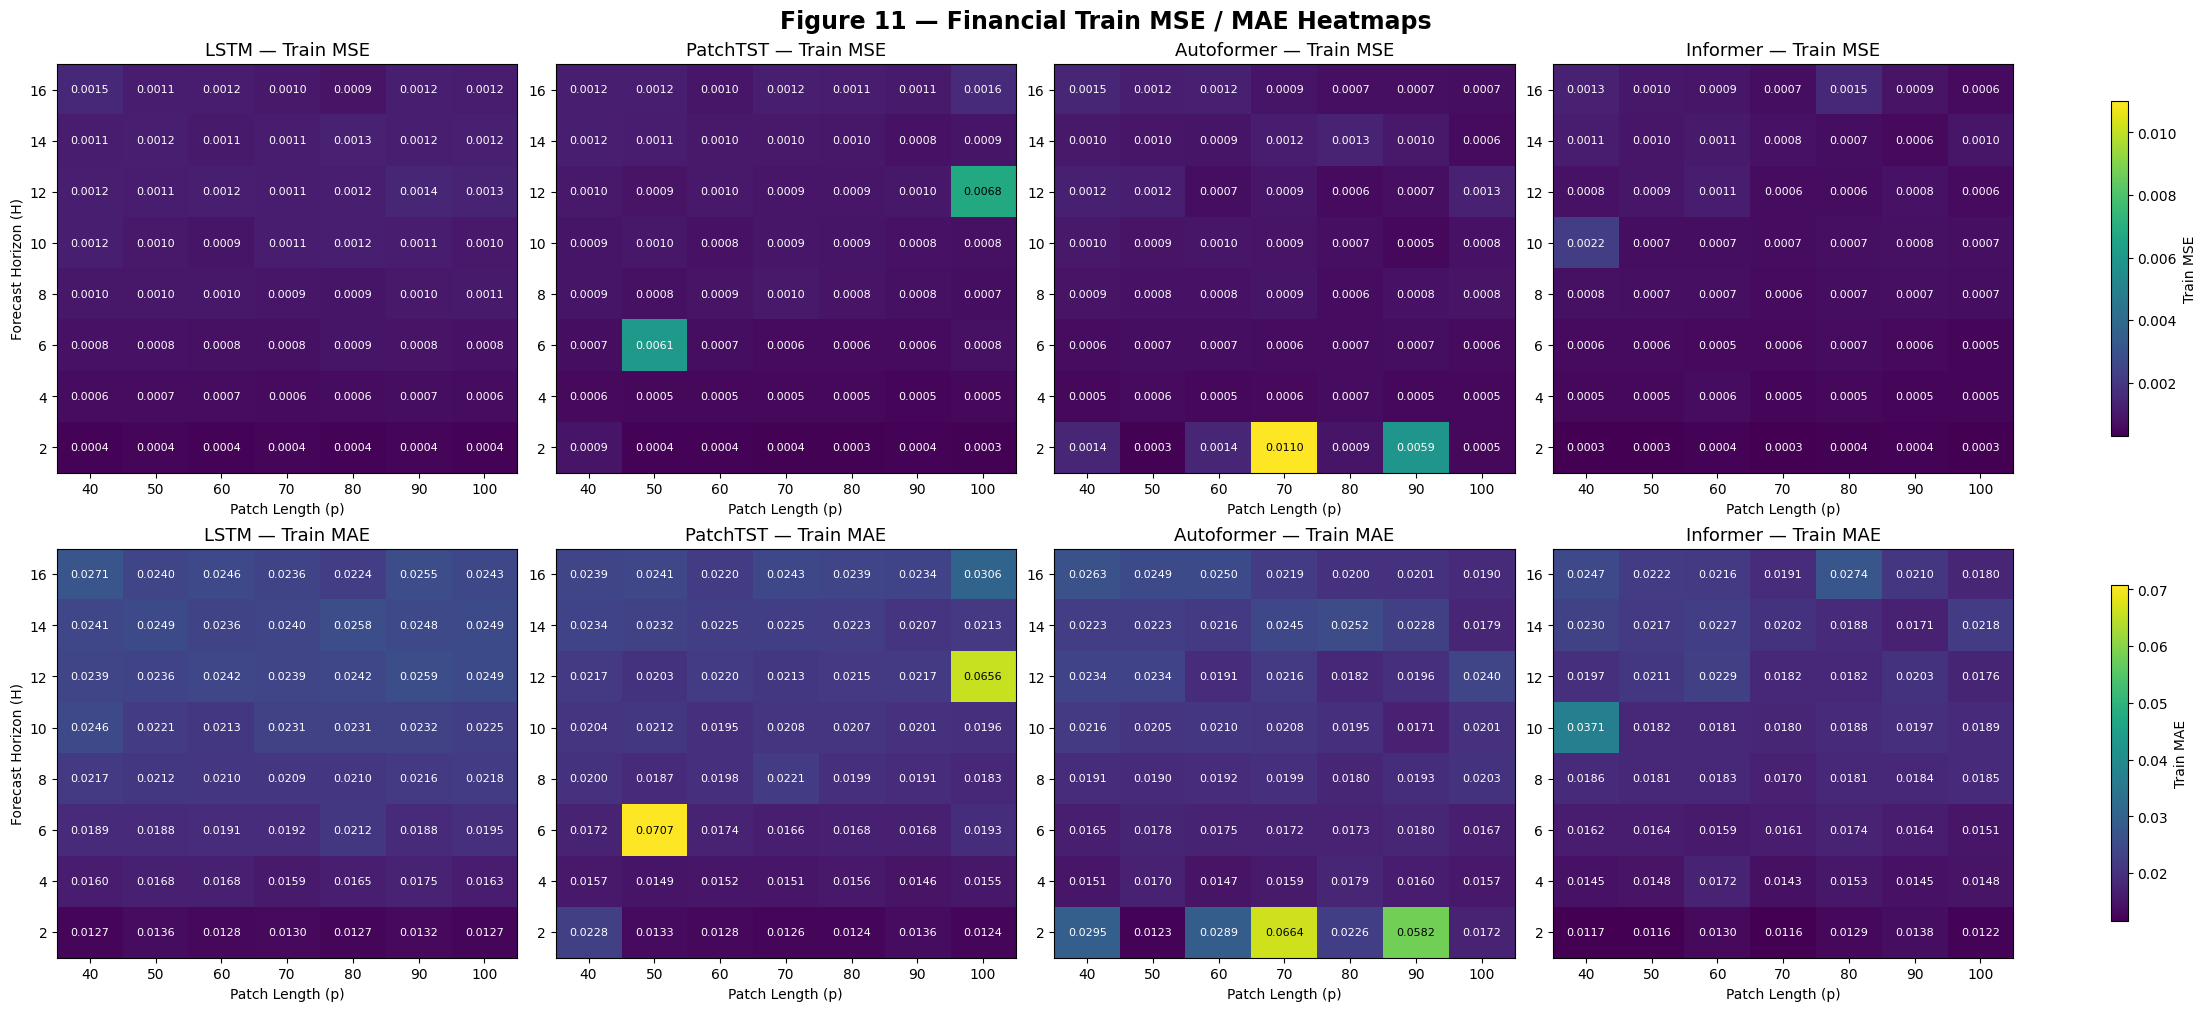

In [2]:
# 1. Chỉ lấy kết quả trên tập Train
train_df = df[df["Set"] == "Train"].copy()

# 2. Tạo figure gồm 2 hàng x 4 cột
fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(22, 10),
    constrained_layout=True
)

metrics = ["MSE", "MAE"]

# 3. Vẽ heatmap cho từng metric
for row, metric in enumerate(metrics):

    # Dùng cùng thang màu cho cả 4 mô hình trong cùng 1 metric
    vmin = train_df[metric].min()
    vmax = train_df[metric].max()

    for col, model in enumerate(models):

        # Lọc dữ liệu theo model
        model_df = train_df[
            train_df["Model"] == model
        ]

        # Pivot thành ma trận:
        # hàng = PatchLen, cột = Horizon
        heatmap_data = model_df.pivot(
            index="Horizon",
            columns="PatchLen",
            values=metric
        ).reindex(index=horizons, columns=patches)

        values = heatmap_data.values

        # 4. Vẽ heatmap
        im = axes[row, col].imshow(
            values,
            cmap="viridis",
            aspect="auto",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        axes[row, col].set_title(
            f"{model} — Train {metric}",
            fontsize=13
        )

        axes[row, col].set_xticks(range(len(patches)), patches)
        axes[row, col].set_yticks(range(len(horizons)), horizons)

        axes[row, col].set_xlabel("Patch Length (p)")

        if col == 0:
            axes[row, col].set_ylabel("Forecast Horizon (H)")
        else:
            axes[row, col].set_ylabel("")

        # 5. Ghi số lên từng ô
        for i in range(values.shape[0]):      # hàng
            for j in range(values.shape[1]):  # cột
                val = values[i, j]

                # Chọn màu chữ để dễ nhìn
                norm_val = (val - vmin) / (vmax - vmin + 1e-12)
                text_color = "white" if norm_val < 0.55 else "black"

                axes[row, col].text(
                    j, i,
                    f"{val:.4f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=text_color
                )

    # 6. Colorbar cho từng hàng metric
    fig.colorbar(
        im,
        ax=axes[row, :],
        label=f"Train {metric}",
        shrink=0.82
    )

fig.suptitle(
    "Figure 11 — Financial Train MSE / MAE Heatmaps",
    fontsize=17,
    fontweight="bold"
)

# 7. Lưu Figure 11
safe_save_figure(
    fig,
    "figure11_financial_train_heatmaps.png"
)

plt.show()


## Figure 12 — Financial Test Heatmaps

Trực quan hóa MSE và MAE của bốn mô hình trên tập Test.

Giữ nguyên không gian Grid Search như Figure 11 để so sánh kết quả Train và Test.

Các giá trị được lấy trực tiếp từ 224 dòng Test trong `metrics.csv`.

Hai Figure sử dụng thang màu riêng theo từng tập dữ liệu, vì vậy cần dựa trên các giá trị MSE/MAE khi so sánh.

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\03_financial\figures\figure12_financial_test_heatmaps.png


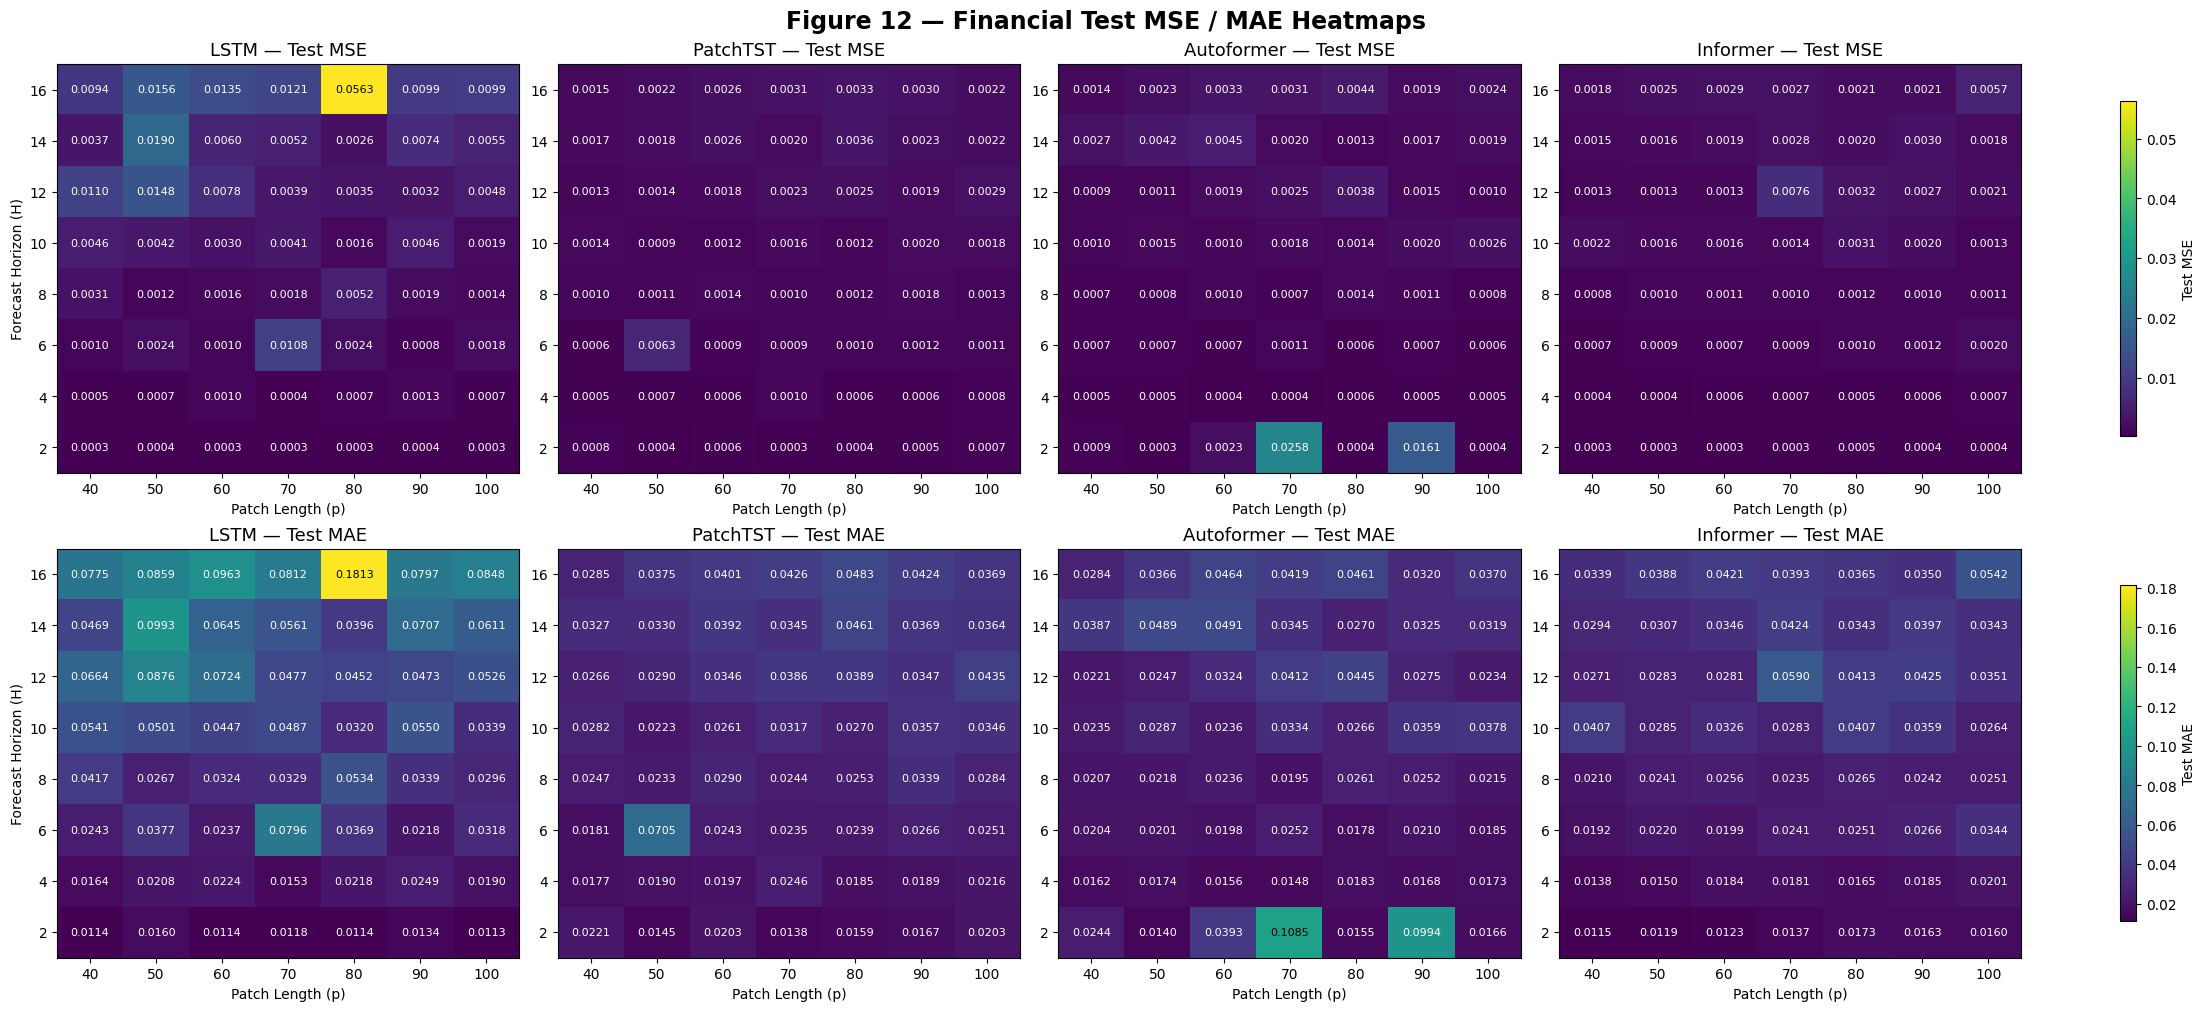

In [3]:
# 1. Chỉ lấy kết quả trên tập Test
test_df = df[df["Set"] == "Test"].copy()

# Kiểm tra dữ liệu Test
assert len(test_df) == 224
assert test_df[["MSE", "MAE"]].notna().all().all()

# 2. Tạo figure gồm 2 hàng x 4 cột
fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(22, 10),
    constrained_layout=True
)

# 3. Vẽ heatmap cho MSE và MAE
for row, metric in enumerate(metrics):

    # Thang màu chung giữa 4 mô hình
    vmin = test_df[metric].min()
    vmax = test_df[metric].max()

    for col, model in enumerate(models):

        ax = axes[row, col]

        # Lọc dữ liệu theo mô hình
        model_df = test_df[
            test_df["Model"] == model
        ]

        # Hàng = Forecast Horizon
        # Cột = Patch Length
        heatmap_data = model_df.pivot(
            index="Horizon",
            columns="PatchLen",
            values=metric
        ).reindex(
            index=horizons,
            columns=patches
        )

        values = heatmap_data.to_numpy()

        # Kiểm tra ma trận 8 x 7
        assert values.shape == (8, 7)
        assert np.isfinite(values).all()

        # 4. Vẽ heatmap
        im = ax.imshow(
            values,
            cmap="viridis",
            aspect="auto",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        ax.set_title(
            f"{model} — Test {metric}",
            fontsize=13
        )

        ax.set_xticks(range(len(patches)), patches)
        ax.set_yticks(range(len(horizons)), horizons)

        ax.set_xlabel("Patch Length (p)")

        if col == 0:
            ax.set_ylabel("Forecast Horizon (H)")

        # 5. Hiển thị giá trị trong từng ô
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):

                val = values[i, j]

                norm_val = (
                    (val - vmin)
                    / (vmax - vmin + 1e-12)
                )

                text_color = (
                    "white" if norm_val < 0.55
                    else "black"
                )

                ax.text(
                    j, i,
                    f"{val:.4f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=text_color
                )

    # 6. Colorbar chung cho cả hàng
    fig.colorbar(
        im,
        ax=axes[row, :],
        label=f"Test {metric}",
        shrink=0.82
    )

# 7. Tiêu đề
fig.suptitle(
    "Figure 12 — Financial Test MSE / MAE Heatmaps",
    fontsize=17,
    fontweight="bold"
)

# 8. Lưu Figure 12
safe_save_figure(
    fig,
    "figure12_financial_test_heatmaps.png"
)

plt.show()


## Figures 13–14 — Financial Test Forecasting

So sánh Ground Truth với dự báo của bốn mô hình trên hai segment BTC.

Cấu hình:

| Figure | Patch length | Horizon | d_model |
|---|---:|---:|---:|
| 13 | 40 | 16 | 48 |
| 14 | 80 | 16 | 48 |

Mỗi hình gồm hai biểu đồ, tương ứng với `BTC_segment_1` và `BTC_segment_2`.

Dự báo được đọc từ các checkpoint trong `financial_grid_search_e4000`.

Vector nhãn được làm phẳng theo thứ tự channel-major. Vì vậy, bước dự báo đầu tiên của kênh thứ `c` nằm tại vị trí `c * H`.

Notebook chỉ đọc `pred_test` và `truth_test`, không thực hiện model forward hoặc cập nhật trọng số.

In [5]:
def plot_financial_forecasts(
    patch_len,
    horizon,
    figure_number,
    d_model=48
):
    """
    Dựng Figure Financial Forecasting từ checkpoint đã lưu.

    Không thực hiện model forward hoặc training.
    """

    channels = bundle["channels"]
    num_channels = len(channels)

    # 1. Nạp checkpoint của bốn mô hình
    ckpts = {}

    for model in models:
        path = RESULTS_DIR / (
            f"{model.lower()}_p{patch_len}"
            f"_h{horizon}_d{d_model}.pt"
        )

        ckpt = load_checkpoint(path)

        # Kiểm tra metadata
        assert ckpt["model"] == model
        assert ckpt["patch_len"] == patch_len
        assert ckpt["horizon"] == horizon
        assert ckpt["d_model"] == d_model
        assert ckpt["input_dim"] == num_channels
        assert ckpt["epochs"] == 4000
        assert ckpt["data_hash"] == EXPECTED_HASH
        assert ckpt["channels"] == channels

        ckpts[model] = ckpt


    # 2. Đọc Ground Truth và predictions
    truth = ckpts["LSTM"]["truth_test"].numpy()

    predictions = {
        model: ckpts[model]["pred_test"].numpy()
        for model in models
    }

    # Bốn checkpoint phải sử dụng cùng Ground Truth
    for model in models:
        np.testing.assert_array_equal(
            ckpts[model]["truth_test"].numpy(),
            truth
        )

        assert predictions[model].shape == truth.shape

    assert truth.shape[1] == num_channels * horizon

    # Kiểm tra số cửa sổ Test theo đúng quy tắc gốc
    expected_windows = (
        len(bundle["test"]) - patch_len - horizon
    )

    assert truth.shape[0] == expected_windows


    # 3. Style của các mô hình
    styles = {
        "LSTM": {
            "color": "tab:blue",
            "linestyle": "-",
            "label": "LSTM"
        },
        "PatchTST": {
            "color": "tab:orange",
            "linestyle": "--",
            "label": "DeepKoopFormer-PatchTST"
        },
        "Autoformer": {
            "color": "tab:green",
            "linestyle": "-.",
            "label": "DeepKoopFormer-Autoformer"
        },
        "Informer": {
            "color": "tab:red",
            "linestyle": ":",
            "label": "DeepKoopFormer-Informer"
        }
    }


    # 4. Tạo Figure gồm hai kênh BTC
    fig, axes = plt.subplots(
        nrows=num_channels,
        ncols=1,
        figsize=(16, 8),
        sharex=True
    )

    axes = np.atleast_1d(axes)

    # Vị trí của bước dự báo đầu tiên trên tập Test
    time_indices = np.arange(len(truth)) + patch_len


    # 5. Vẽ từng kênh
    for c in range(num_channels):
        ax = axes[c]

        # Flatten channel-major:
        # [channel_0(t1...tH), channel_1(t1...tH)]
        idx = c * horizon

        ax.plot(
            time_indices,
            truth[:, idx],
            color="black",
            linewidth=2,
            label="Ground Truth"
        )

        for model in models:
            ax.plot(
                time_indices,
                predictions[model][:, idx],
                linewidth=1.5,
                **styles[model]
            )

        ax.set_title(
            f"({chr(97 + c)}) {channels[c]}",
            fontsize=13
        )

        ax.set_ylabel("Normalized Close Price")
        ax.grid(True, alpha=0.3)

    axes[-1].set_xlabel("Time Index (Test Set)")


    # 6. Tiêu đề và chú giải
    fig.suptitle(
        f"Figure {figure_number} — "
        "DeepKoopFormer vs LSTM\n"
        "Financial Forecasting (Test Set)\n"
        f"P={patch_len}, H={horizon}, "
        f"d_model={d_model} | First forecast step",
        fontsize=16,
        fontweight="bold",
        y=0.99
    )

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.015),
        ncol=3,
        frameon=False
    )

    fig.subplots_adjust(
        top=0.80,
        bottom=0.15,
        hspace=0.25
    )


    # 7. Lưu Figure đúng số và đúng thư mục
    filename = (
        f"figure{figure_number}_"
        "financial_test_forecasts.png"
    )

    safe_save_figure(fig, filename)

    plt.show()

    print(
        f"Figure {figure_number}: "
        f"P={patch_len}, H={horizon}, "
        f"Test windows={len(truth)}"
    )

c:\Users\Win 11 New\Desktop\pa gk\.venv\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\03_financial\figures\figure13_financial_test_forecasts.png


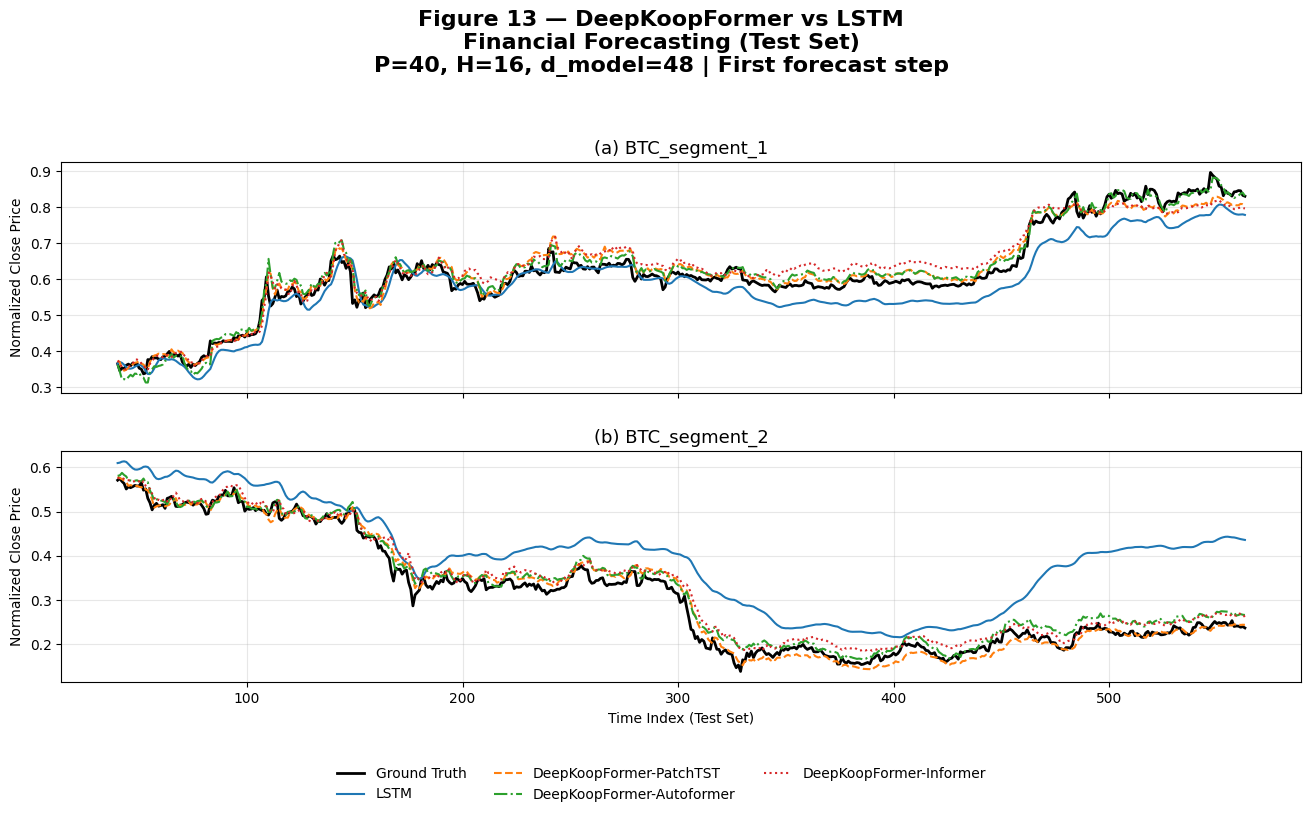

Figure 13: P=40, H=16, Test windows=524
Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\03_financial\figures\figure14_financial_test_forecasts.png


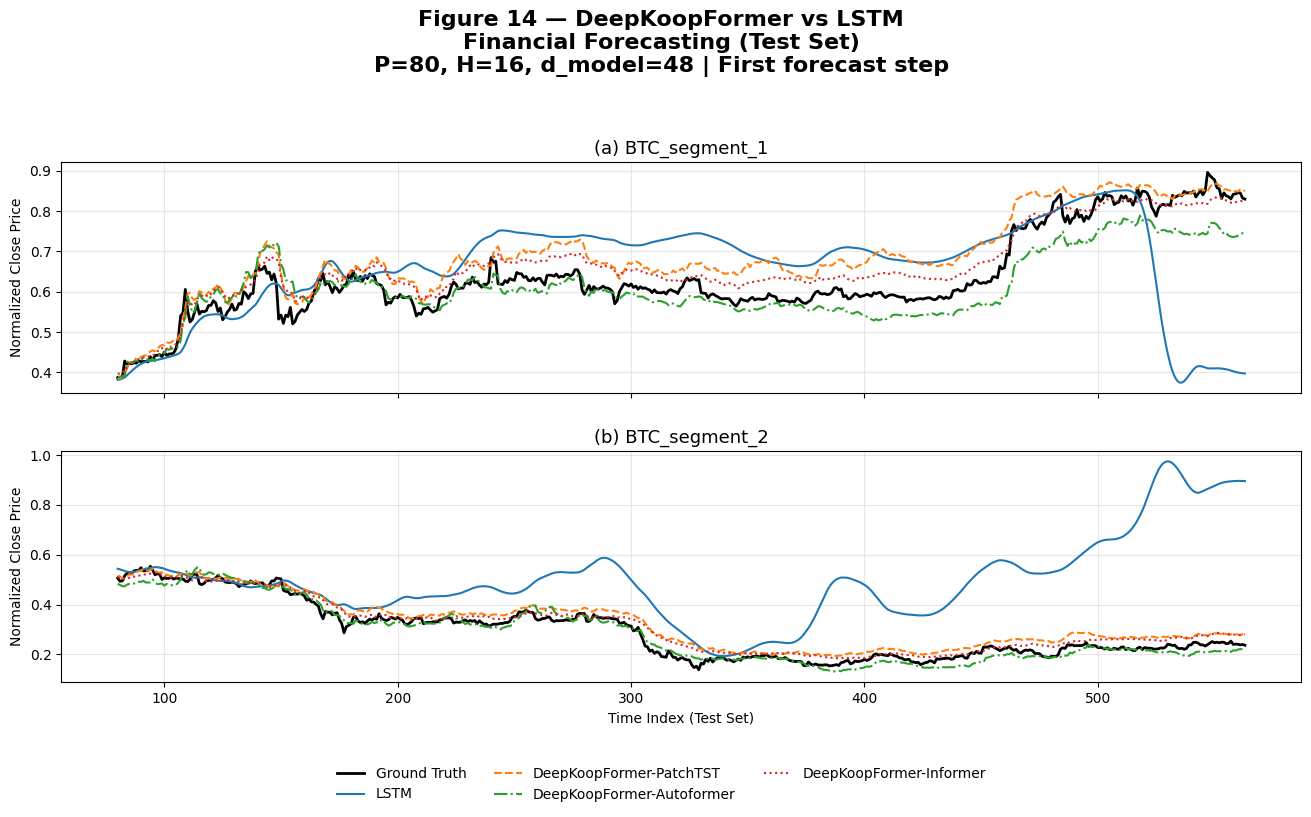

Figure 14: P=80, H=16, Test windows=484


In [ ]:
# GENERATE FIGURE 13 AND FIGURE 14

# Figure 13 — P=40, H=16
plot_financial_forecasts(
    patch_len=40,
    horizon=16,
    figure_number=13,
    d_model=48
)

# Figure 14 — P=80, H=16
plot_financial_forecasts(
    patch_len=80,
    horizon=16,
    figure_number=14,
    d_model=48
)

## Phân tích bổ sung — Model Comparison

Tổng hợp MSE và MAE của bốn mô hình theo tập Train và Test.

Các thống kê bao gồm trung bình và trung vị.

Bảng xếp hạng sử dụng MSE trung bình trên tập Test.

Ngoài ra, so sánh riêng cấu hình Figure 14 (`P=80`, `H=16`, `d_model=48`).

Dữ liệu được đọc từ `metrics.csv`. Notebook chỉ hiển thị bảng, không ghi lại CSV.

In [8]:
# 1. Tổng hợp MSE và MAE theo mô hình và tập dữ liệu
summary = (
    df.groupby(["Set", "Model"])
      .agg(
          Mean_MSE=("MSE", "mean"),
          Median_MSE=("MSE", "median"),
          Mean_MAE=("MAE", "mean"),
          Median_MAE=("MAE", "median")
      )
      .reset_index()
)

# 2. Xếp hạng dựa trên Test MSE trung bình
test_summary = (
    summary[summary["Set"] == "Test"]
    .sort_values("Mean_MSE")
    .reset_index(drop=True)
)

test_summary.insert(
    0,
    "Rank",
    range(1, len(test_summary) + 1)
)

print("=== FINANCIAL MODEL COMPARISON — TEST SET ===")
display(test_summary.round(6))


# 3. So sánh riêng cấu hình Figure 14
fig14_metrics = df[
    (df["PatchLen"] == 80) &
    (df["Horizon"] == 16)
].copy()

fig14_table = fig14_metrics.pivot(
    index="Model",
    columns="Set",
    values=["MSE", "MAE"]
)

# Đặt lại tên các cột cho dễ đọc
fig14_table.columns = [
    f"{set_name}_{metric}"
    for metric, set_name in fig14_table.columns
]

fig14_table = fig14_table.sort_values("Test_MSE")

print("\n=== FIGURE 14 — P=80, H=16 ===")
display(fig14_table.round(6))


# 4. Chỉ hiển thị bảng tổng hợp, không ghi CSV
print("\n=== FINANCIAL SUMMARY ===")
display(summary.round(6))

print("Read-only analysis completed.")

=== FINANCIAL MODEL COMPARISON — TEST SET ===


,Rank,Set,Model,Mean_MSE,Median_MSE,Mean_MAE,Median_MAE
0,1,Test,PatchTST,0.001567,0.001305,0.029492,0.027607
1,2,Test,Informer,0.001577,0.001303,0.028219,0.026868
2,3,Test,Autoformer,0.002190,0.001091,0.030213,0.025198
3,4,Test,LSTM,0.005229,0.002839,0.046361,0.040631



=== FIGURE 14 — P=80, H=16 ===


,Test_MSE,Train_MSE,Test_MAE,Train_MAE
Model,,,,
Informer,0.002147,0.001489,0.036545,0.027369
PatchTST,0.003336,0.001126,0.048274,0.023873
Autoformer,0.004375,0.000734,0.046138,0.020018
LSTM,0.056312,0.000878,0.181281,0.022410



=== FINANCIAL SUMMARY ===


,Set,Model,Mean_MSE,Median_MSE,Mean_MAE,Median_MAE
0,Test,Autoformer,0.002190,0.001091,0.030213,0.025198
1,Test,Informer,0.001577,0.001303,0.028219,0.026868
2,Test,LSTM,0.005229,0.002839,0.046361,0.040631
3,Test,PatchTST,0.001567,0.001305,0.029492,0.027607
4,Train,Autoformer,0.001111,0.000812,0.021543,0.019736
5,Train,Informer,0.000718,0.000674,0.018200,0.018139
6,Train,LSTM,0.000940,0.001004,0.020811,0.021791
7,Train,PatchTST,0.001013,0.000855,0.021136,0.020184


Read-only analysis completed.
